# Estimativas e tamanhos de efeito

[▶ Abrir este notebook no Google Colab](https://colab.research.google.com/github/lalvim/disciplina_computacao_aplicada_humanidades_digitais/blob/main/unidade_05/01_estimativas_e_tamanhos_de_efeito.ipynb)

O guia definiu uma comparação como uma cadeia argumentativa. Este notebook
começa pela pergunta mais concreta: **quanto os grupos diferem na amostra ou no
corpus observado?**

## 1. Unidades, grupos e quantidade de interesse

Compare apenas unidades que tenham significado compatível. Aqui cada linha é um
documento; usaremos `local` para formar grupos e `palavras` como extensão
simulada. A média responde sobre a extensão média; a mediana, sobre a posição
central resistente a extremos; a proporção, sobre a frequência de uma condição.

![Diferença observada, incerteza do procedimento e relevância substantiva aparecem como três perguntas distintas ligadas em sequência.](https://github.com/lalvim/disciplina_computacao_aplicada_humanidades_digitais/blob/main/unidade_05/imagens/01_diferenca_incerteza_relevancia.svg?raw=1)

Defina a quantidade antes de calcular. Se $\hat{\theta}_A$ e
$\hat{\theta}_B$ são estimativas nos grupos, a diferença absoluta é:

$$
\Delta=\hat{\theta}_A-\hat{\theta}_B.
$$

O sinal depende da ordem declarada.

> **Nota de adaptação.** As células a seguir substituem `dados/documentos.csv`
> (24 registros fictícios, grupos `Capital`/`Interior`) pela base real do projeto —
> `dados/derivados/documentos_processaveis.csv`, 12 discursos de posse, 1985–2023.
> Grupo formado a partir de H2 (Unidade 4, Notebook 00): **Pontas** = discursos de
> 1985, 1990, 1995, 2019 e 2023; **Centro** = 1992, 1999, 2003, 2007, 2011, 2015 e
> 2016. A quantidade de interesse é `taxa_liberdade_mil` (ocorrências de
> "liberdade/liberdades" por 1.000 palavras), não `palavras`: a pergunta do projeto
> é sobre o termo, e a Unidade 4 já mostrou que a contagem bruta é distorcida pela
> extensão dos discursos. `graficos.estimativas_grupos` não está disponível fora do
> repositório da disciplina; a distribuição é mostrada com boxplot e pontos
> individuais.

In [1]:
# @title Preparação do ambiente — execute esta célula no Google Colab
from pathlib import Path
import importlib.util
import os
import subprocess
import sys

URL_REPOSITORIO = 'https://github.com/lalvim/disciplina_computacao_aplicada_humanidades_digitais.git'
REPOSITORIO = Path(
    "/content/disciplina_computacao_aplicada_humanidades_digitais"
)
PASTA_UNIDADE = REPOSITORIO / 'unidade_05'

try:
    import google.colab  # type: ignore  # noqa: F401
    EM_COLAB = True
except ImportError:
    EM_COLAB = False

if EM_COLAB:
    if not (REPOSITORIO / ".git").exists():
        subprocess.run(
            [
                "git",
                "clone",
                "--depth",
                "1",
                "--branch",
                "main",
                URL_REPOSITORIO,
                str(REPOSITORIO),
            ],
            check=True,
        )

    PACOTES_COLAB = []
    ausentes = [
        especificacao
        for modulo, especificacao in PACOTES_COLAB
        if importlib.util.find_spec(modulo) is None
    ]
    if ausentes:
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", *ausentes],
            check=True,
        )

    os.chdir(PASTA_UNIDADE)
    print("Ambiente preparado em:", Path.cwd())
else:
    print("Ambiente local: nenhuma clonagem necessária.")

Ambiente local: nenhuma clonagem necessária.


,count,mean,median,std
grupo,,,,
Centro,7,0.349,0.365,0.398
Pontas,5,2.842,2.650,1.254


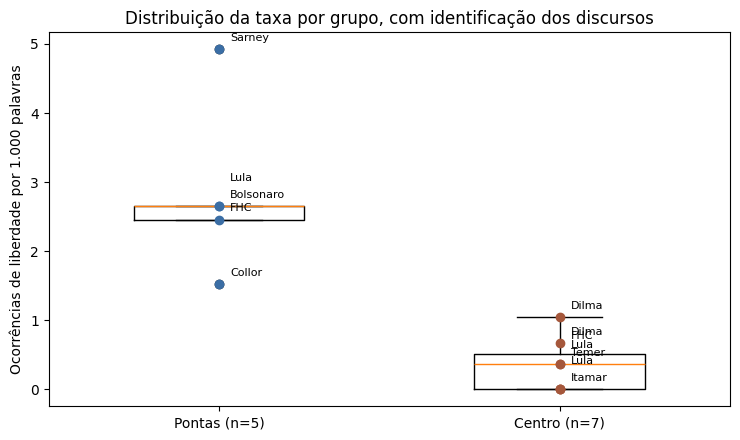

In [2]:
import math
import pandas as pd
import matplotlib.pyplot as plt

docs = pd.read_csv("dados/derivados/documentos_processaveis.csv").sort_values("ano")

PONTAS = {1985, 1990, 1995, 2019, 2023}
docs["grupo"] = docs["ano"].map(lambda a: "Pontas" if a in PONTAS else "Centro")

CURTO = {"José Sarney": "Sarney", "Fernando Collor de Mello": "Collor",
         "Itamar Franco": "Itamar", "Fernando Henrique Cardoso": "FHC",
         "Luiz Inácio Lula da Silva": "Lula", "Dilma Rousseff": "Dilma",
         "Michel Temer": "Temer", "Jair Bolsonaro": "Bolsonaro"}
docs["curto"] = docs["presidente"].map(CURTO)

resumo_grupos = docs.groupby("grupo")["taxa_liberdade_mil"].agg(["count", "mean", "median", "std"])
display(resumo_grupos.round(3))

fig, ax = plt.subplots(figsize=(7.5, 4.5))
posicoes = {"Pontas": 1, "Centro": 2}
for grupo, cor in [("Pontas", "#3b6ea5"), ("Centro", "#a5573b")]:
    sub = docs.loc[docs.grupo == grupo].sort_values("taxa_liberdade_mil")
    y = sub["taxa_liberdade_mil"].tolist()
    x = [posicoes[grupo]] * len(y)
    ax.scatter(x, y, color=cor, zorder=3)
    deslocamentos = [6, 6]
    ultimo_y = None
    passo = 0
    for xi, yi, rot in zip(x, y, sub["curto"]):
        if ultimo_y is not None and abs(yi - ultimo_y) < 0.18:
            passo += 12
        else:
            passo = 0
        ax.annotate(rot, (xi, yi), textcoords="offset points",
                    xytext=(8, 6 + passo), fontsize=8)
        ultimo_y = yi
ax.boxplot([docs.loc[docs.grupo == g, "taxa_liberdade_mil"] for g in ["Pontas", "Centro"]],
           positions=[1, 2], widths=.5)
ax.set_xticks([1, 2]); ax.set_xticklabels(["Pontas (n=5)", "Centro (n=7)"])
ax.set_ylabel("Ocorrências de liberdade por 1.000 palavras")
ax.set_title("Distribuição da taxa por grupo, com identificação dos discursos")
plt.tight_layout(); plt.show()

A tabela e o gráfico mostram distribuição, sobreposição e um caso extremo. Por
isso, uma única medida não deve apagar a forma dos grupos.

## 2. Médias, medianas e proporções

Para cada medida, calcularemos Pontas menos Centro. A proporção corresponde aos
discursos com pelo menos uma ocorrência de "liberdade/liberdades"; ela não mede a
intensidade do termo no texto, só sua presença.

In [3]:
por_grupo = docs.groupby("grupo")
medidas = pd.DataFrame({
    "media_taxa": por_grupo["taxa_liberdade_mil"].mean(),
    "mediana_taxa": por_grupo["taxa_liberdade_mil"].median(),
    "proporcao_menciona": por_grupo["ocorrencias_liberdade"].apply(lambda s: s.gt(0).mean()),
})
diferencas = medidas.loc["Pontas"] - medidas.loc["Centro"]
display(medidas.round(3))
diferencas.rename("Pontas menos Centro").round(3)

,media_taxa,mediana_taxa,proporcao_menciona
grupo,,,
Centro,0.349,0.365,0.571
Pontas,2.842,2.650,1.000


media_taxa            2.493
mediana_taxa          2.285
proporcao_menciona    0.429
Name: Pontas menos Centro, dtype: float64

Média e mediana respondem a aspectos diferentes, e a diferença de proporções é
lida em pontos percentuais. A escolha deve preceder a observação do resultado.

## 3. Diferenças absolutas e relativas

Tomando Centro como referência, a diferença relativa é:

$$
\Delta_{rel}=\frac{\hat{\theta}_A-\hat{\theta}_B}{\hat{\theta}_B}.
$$

Ela muda ao inverter a referência e se torna instável quando o denominador se
aproxima de zero. Sempre apresente também a diferença absoluta e a unidade.

In [4]:
media_pontas = medidas.loc["Pontas", "media_taxa"]
media_centro = medidas.loc["Centro", "media_taxa"]
diferenca_absoluta = media_pontas - media_centro
diferenca_relativa = diferenca_absoluta / media_centro
pd.Series({
    "diferença absoluta (ocorrências/mil palavras)": diferenca_absoluta,
    "diferença relativa a Centro": diferenca_relativa,
}).round(3)

diferença absoluta (ocorrências/mil palavras)    2.493
diferença relativa a Centro                      7.143
dtype: float64

A diferença relativa produz uma narrativa proporcional, mas não informa a
variabilidade interna. Para comparar escalas, pode-se padronizar a diferença;
ainda assim, a escala original permanece indispensável.

## 4. Tamanho de efeito

Para duas médias, uma versão introdutória da diferença padronizada é:

$$
d=\frac{\bar{x}_A-\bar{x}_B}{s_p},\qquad
s_p=\sqrt{\frac{(n_A-1)s_A^2+(n_B-1)s_B^2}{n_A+n_B-2}}.
$$

`d` expressa a diferença em desvios-padrão combinados. Rótulos universais como
“pequeno” ou “grande” não substituem conhecimento substantivo, desenho dos dados
ou diferença bruta.

In [5]:
a = docs.loc[docs.grupo == "Pontas", "taxa_liberdade_mil"]
b = docs.loc[docs.grupo == "Centro", "taxa_liberdade_mil"]
desvio_combinado = math.sqrt(
    ((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1))
    / (len(a) + len(b) - 2)
)
d_padronizado = (a.mean() - b.mean()) / desvio_combinado
pd.Series({"diferença bruta": a.mean() - b.mean(), "d padronizado": d_padronizado}).round(3)

diferença bruta    2.493
d padronizado      2.930
dtype: float64

O efeito padronizado resume separação relativa à dispersão, mas pode mudar com
um único caso influente. A etapa seguinte retorna aos registros.

## 5. Sensibilidade e relevância substantiva

Compare a diferença de médias com e sem `DISCURSO_1985_SARNEY`, a maior taxa do
corpus. Depois leia os trechos dos discursos com maiores e menores valores.
Pergunte se `taxa_liberdade_mil` representa intensidade do conceito ou apenas
frequência de um lexema.

In [6]:
sem_sarney = docs.loc[~docs["id_doc"].eq("DISCURSO_1985_SARNEY")].copy()
sem_sarney["grupo"] = sem_sarney["ano"].map(lambda a: "Pontas" if a in PONTAS else "Centro")
sensibilidade = pd.Series({
    "todos os registros": diferenca_absoluta,
    "sem Sarney 1985": (
        sem_sarney.loc[sem_sarney["grupo"].eq("Pontas"), "taxa_liberdade_mil"].mean()
        - sem_sarney.loc[sem_sarney["grupo"].eq("Centro"), "taxa_liberdade_mil"].mean()
    ),
})
display(sensibilidade.round(3))

trechos = pd.read_csv("dados/derivados/discursos_trechos.csv")
maiores = docs.nlargest(3, "taxa_liberdade_mil")[["id_doc", "ano", "taxa_liberdade_mil", "palavras"]]
menores = docs[docs["ocorrencias_liberdade"].eq(0)][["id_doc", "ano", "taxa_liberdade_mil", "palavras"]]
display(maiores)
display(menores)

for id_doc in maiores["id_doc"]:
    exemplo = trechos.loc[trechos.id_doc.eq(id_doc), "sentenca_alvo"].iloc[0]
    print(f"[{id_doc}] {exemplo[:150]}")

todos os registros    2.493
sem Sarney 1985       1.973
dtype: float64

,id_doc,ano,taxa_liberdade_mil,palavras
0,DISCURSO_1985_SARNEY,1985,4.922280,3860
11,DISCURSO_2023_LULA,2023,2.658564,2633
10,DISCURSO_2019_BOLSONARO,2019,2.650177,1132


,id_doc,ano,taxa_liberdade_mil,palavras
2,DISCURSO_1992_ITAMAR,1992,0.0,614
5,DISCURSO_2003_LULA,2003,0.0,3881
6,DISCURSO_2007_LULA,2007,0.0,3833


[DISCURSO_1985_SARNEY] Respira-se liberdade.
[DISCURSO_2023_LULA] as mais violentas ameaças à liberdade do voto, a mais abjeta campanha de mentiras e de ódio tramada para manipular e constranger o eleitorado.
[DISCURSO_2019_BOLSONARO] Por isso, quando inimigos da pátria, da ordem e da liberdade tentaram pôr fim a minha vida, milhões de brasileiros foram às ruas.


## U05-A02 — Atividade integrada — quadro de estimativas

**Modalidade:** individual e revisão em dupla. **Tempo:** 25 + 10 minutos.

1. escolha dois grupos e uma quantidade coerente com sua pergunta;
2. apresente a distribuição e ao menos duas medidas pertinentes;
3. calcule diferença absoluta e, se defensável, relativa ou padronizada;
4. inspecione dois casos que qualifiquem o resultado;
5. escreva o que a diferença significa e o que não significa.

**Minha estimativa e justificativa**

- **Grupos e quantidade:** Pontas (1985, 1990, 1995, 2019, 2023; n = 5) vs. Centro
  (1992, 1999, 2003, 2007, 2011, 2015, 2016; n = 7); quantidade: `taxa_liberdade_mil`.
- **Distribuição:** média Pontas 2,842, mediana 2,650, desvio-padrão 1,254 (n = 5);
  média Centro 0,349, mediana 0,365, desvio-padrão 0,398 (n = 7). Os grupos quase não
  se sobrepõem — o menor valor de Pontas (1,521, Collor) já fica acima do maior valor
  de Centro (1,045, Dilma 2011).
- **Diferença absoluta:** 2,493 ocorrências/mil palavras (Pontas menos Centro).
- **Diferença relativa a Centro:** 714% — instável, porque a média de Centro (0,349)
  está perto de zero; reporto para registro, não como leitura principal.
- **Diferença padronizada:** d = 2,930 (desvio combinado 0,851). Em qualquer rótulo
  convencional isso seria "grande", mas com n = 5 e n = 7 o rótulo importa menos do
  que a diferença bruta acima.
- **Proporção que menciona o termo:** 100% em Pontas (5/5) contra 57,1% em Centro
  (4/7) — diferença de 0,429 (42,9 pontos percentuais).

**Casos inspecionados**

- **Sarney 1985** (maior taxa do corpus, 4,922): *"Respira-se liberdade"*; *"a
  liberdade é um legado de Deus"*. Uso afirmativo e programático, coerente com o
  momento de transição do regime.
- **Itamar 1992, Lula 2003 e Lula 2007** (as três taxas iguais a zero, todas no
  grupo Centro): discurso de posse pós-impeachment mínimo (Itamar, 614 palavras) e
  dois discursos longos (3.881 e 3.833 palavras) sem nenhuma ocorrência do lexema —
  o zero não é um artefato de brevidade em dois dos três casos.

**Relevância substantiva e limite**

Sem Sarney 1985, a diferença absoluta cai de 2,493 para 1,973 — ainda separa os
grupos com folga, então o padrão não depende de um único caso. `taxa_liberdade_mil`
mede frequência de um lexema, não intensidade de um conceito: Lula usa "liberdade"
zero vezes em 2003 e 2007 e sete vezes em 2023, sem que isso implique que a noção
esteve ausente dos dois primeiros discursos ou mais presente no terceiro — em 2023 o
termo é em parte usado para **recusar** o sentido que o adversário lhe atribui, não
só para afirmá-lo (ver trechos na Unidade 4). A diferença observada é grande e
consistente, mas com n = 5 e n = 7, sobre uma base completa (todas as posses do
período, não uma amostra), qualquer teste de significância seria decorativo: o
resultado relevante aqui é a diferença descritiva em si, não um valor de p.

Leve o quadro ao Notebook 02. Ele será acompanhado por uma avaliação explícita
da variabilidade e das condições em que a inferência é pertinente.